# Modèle de l'activité « normale » – Divvy Chicago (trajets journaliers)

**Objectif :** estimer le nombre de trajets *attendu* chaque jour à partir de facteurs « normaux » (saison, jour de la semaine, jours fériés, taille du réseau), puis repérer les jours où l'observé sort de l'intervalle de prédiction = **événements anormaux**.

**Modèle A (sans météo)** : binomiale négative (NB2) avec dispersion α **estimée** + refit robuste (les jours extrêmes sont exclus de l'ajustement pour ne pas tirer la « normale » vers eux).

Les cellules à modifier sont dans la section **1. Configuration**.

## 1. Configuration

In [64]:
COUNTS_PATH  = "data/daily_counts_city.csv"   # colonnes: date, n_trips [, n_active_stations]
NETWORK_COL  = "n_active_stations"            # taille du réseau (stations actives / jour). Si absente -> spline du temps
N_HARMONICS  = 3        # complexité du cycle annuel (Fourier)
LEVEL        = 0.99     # niveau de l'intervalle de prédiction (1 % de jours « anormaux » attendus par hasard)
Z_CLIP       = 3.0      # refit robuste : jours avec |résidu| > Z_CLIP exclus de l'ajustement
ROBUST_ROUNDS = 2
START, END = "2021-12-01", "2026-01-31"           # fitting window (with margin)
REPORT_START, REPORT_END = "2022-01-01", "2025-12-31"

## 2. Imports

In [65]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.tsa.stattools import acf

try:
    import holidays
except ImportError:
    %pip install holidays
    import holidays
%matplotlib inline

## 3. Calendrier
Seuls les jours fériés qui ont un vrai effet sont retenus comme « majeurs ». Les autres jours de la liste Illinois (Pulaski, Lincoln, Columbus…) sont des jours ordinaires pour la plupart des gens.
Les vacances scolaires approximatives ont été **retirées** : elles se confondaient avec l'été (effet saisonnier) et les dates de printemps étaient fausses.

In [77]:
MAJOR_KEYWORDS = ("New Year", "Memorial", "Independence", "Labor", "Thanksgiving", "Christmas")
 
def build_calendar(start=START, end=END):
    cal = pd.DataFrame({"date": pd.date_range(start, end, freq="D")})
    il = holidays.US(state="IL", years=range(cal.date.dt.year.min(), cal.date.dt.year.max() + 1))
    d = cal.date.dt.date
    cal["is_holiday"] = d.isin(il)
    cal["holiday_name"] = d.map(il).fillna("")
    cal["is_major_holiday"] = cal.holiday_name.apply(lambda n: any(k in n for k in MAJOR_KEYWORDS) and "Juneteenth" not in n)
    return cal
 
# Vacances CPS (Chicago Public Schools), dates officielles : (premier jour de congé, dernier jour de congé)
SCHOOL_BREAKS = {
    "winter": [("2021-12-20", "2022-01-02"), ("2022-12-23", "2023-01-06"), ("2023-12-22", "2024-01-07"),
               ("2024-12-23", "2025-01-03"), ("2025-12-22", "2026-01-02")],
    "spring": [("2022-04-11", "2022-04-15"), ("2023-04-03", "2023-04-07"),
               ("2024-03-25", "2024-03-29"), ("2025-03-24", "2025-03-28")],
    # optionnel (voir USE_SUMMER_BREAK) : lendemain du dernier jour de classe -> veille de la rentrée
    "summer": [("2022-06-15", "2022-08-21"), ("2023-06-08", "2023-08-20"),
               ("2024-06-07", "2024-08-25"), ("2025-06-13", "2025-08-17")],
}
 
def add_school_breaks(cal):
    cal = cal.copy()
    for name, periods in SCHOOL_BREAKS.items():
        cal[f"is_{name}_break"] = False
        for start, end in periods:
            cal.loc[(cal.date >= start) & (cal.date <= end), f"is_{name}_break"] = True
    return cal
 
def add_holiday_context(cal):
    """Jours autour des fériés majeurs : veilles, week-ends prolongés, semaine de Thanksgiving."""
    cal = cal.copy().sort_values("date").reset_index(drop=True)
    is_off = cal.is_major_holiday | (cal.date.dt.dayofweek >= 5)          # jour non travaillé
 
    # Blocs de jours non travaillés consécutifs ; un bloc >= 3 jours = week-end prolongé
    block_id = (is_off != is_off.shift()).cumsum()
    block_len = is_off.groupby(block_id).transform("sum")
    has_holiday = cal.is_major_holiday.groupby(block_id).transform("any")
    cal["is_long_weekend"] = is_off & (block_len >= 3) & has_holiday & ~cal.is_major_holiday
 
    # Veille d'un férié majeur (24 déc., 31 déc., 3 juillet...) qui n'est pas déjà un jour off
    next_is_major = cal.is_major_holiday.shift(-1, fill_value=False)
    cal["is_holiday_eve"] = next_is_major & ~is_off
 
    # Semaine de Thanksgiving (lundi -> dimanche) : CPS ferme toute la semaine
    tg = cal.loc[cal.holiday_name.str.contains("Thanksgiving") & ~cal.holiday_name.str.contains("After"), "date"]
    week_starts = set(tg - pd.to_timedelta(tg.dt.dayofweek, unit="D"))
    cal["is_thanksgiving_week"] = (cal.date - pd.to_timedelta(cal.date.dt.dayofweek, unit="D")).isin(week_starts)
 
    # Noël a son propre coefficient (beaucoup plus calme que les autres fériés majeurs)
    cal["is_christmas"] = cal.holiday_name.str.contains("Christmas")
    return cal
 
# --- construction du calendrier (ordre important) ---
calendar_df = build_calendar()
calendar_df = add_school_breaks(calendar_df)
calendar_df = add_holiday_context(calendar_df)
calendar_df.to_csv("data/calendar.csv", index=False)
 
# Vérification : nombre de jours par année pour chaque drapeau
flags = ["is_major_holiday", "is_christmas", "is_long_weekend", "is_holiday_eve", "is_thanksgiving_week",
         "is_winter_break", "is_spring_break", "is_summer_break"]
calendar_df.assign(year=calendar_df.date.dt.year).groupby("year")[flags].sum()
 

,is_major_holiday,is_christmas,is_long_weekend,is_holiday_eve,is_thanksgiving_week,is_winter_break,is_spring_break,is_summer_break
year,,,,,,,,
2021,3,2,1,2,0,12,0,0
2022,7,2,9,1,7,11,5,68
2023,7,1,8,2,7,16,5,74
2024,6,1,4,4,7,16,5,80
2025,6,1,6,4,7,13,5,66
2026,1,0,0,0,0,2,0,0


## 4. Chargement des données et variables explicatives

In [78]:
counts = pd.read_csv(COUNTS_PATH, parse_dates=["date"])
counts = counts[(counts.date >= START) & (counts.date <= END)]
df = counts.merge(calendar_df, on="date", how="left").sort_values("date").reset_index(drop=True)
# Ruptures structurelles : dates (YYYY-MM-DD) où le niveau change durablement (voir diagnostic plus bas). Vide au début.
BREAK_DATES = []        # exemple : ["2023-06-01"]
for i, bd in enumerate(BREAK_DATES):
    df[f"step_{i}"] = (df.date >= bd).astype(int)
step_terms = [f"step_{i}" for i in range(len(BREAK_DATES))]
calendar_terms = ["is_long_weekend", "is_holiday_eve", "is_thanksgiving_week", "is_christmas"]
 
# ... puis, dans la même cellule, remplacer la ligne  break_terms = ...  par :
break_terms = ["is_winter_break", "is_spring_break"] + (["is_summer_break"] if USE_SUMMER_BREAK else []) \
              + calendar_terms + step_terms
# Jours manquants (≠ 0 trajet !)
missing = pd.date_range(df.date.min(), df.date.max()).difference(df.date)
print(f"{len(df)} jours, {len(missing)} jours manquants dans la plage :", [str(m.date()) for m in missing[:10]])

df["dow"] = df.date.dt.day_name()
df["is_weekend"] = (df.date.dt.dayofweek >= 5).astype(int)

# Cycle annuel lisse (Fourier) au lieu de 12 mois en dummies
doy = df.date.dt.dayofyear
for k in range(1, N_HARMONICS + 1):
    df[f"sin{k}"] = np.sin(2 * np.pi * k * doy / 365.25)
    df[f"cos{k}"] = np.cos(2 * np.pi * k * doy / 365.25)
# Le mélange pendulaires/loisirs change avec la saison -> interaction week-end x saison
df["wkend_sin1"] = df.is_weekend * df.sin1
df["wkend_cos1"] = df.is_weekend * df.cos1

# Taille du réseau
if NETWORK_COL in df.columns:
    df["log_network"] = np.log(df[NETWORK_COL].clip(lower=1))
    network_term = "log_network"
else:
    warnings.warn(f"'{NETWORK_COL}' absente: repli sur une spline du temps. Ajoutez le nb de stations actives / jour !")
    df["t"] = (df.date - df.date.min()).dt.days / 365.25
    # bornes fixées sur toute la période, sinon le refit robuste (qui exclut des jours) casse la prédiction
    network_term = f"bs(t, df=6, lower_bound={df.t.min()}, upper_bound={df.t.max()})"

harm = [f"sin{k}" for k in range(1, N_HARMONICS + 1)] + [f"cos{k}" for k in range(1, N_HARMONICS + 1)]
USE_SUMMER_BREAK = False   # l'été est déjà largement capté par le cycle annuel (Fourier)
break_terms = ["is_winter_break", "is_spring_break"] + (["is_summer_break"] if USE_SUMMER_BREAK else [])
formula = "n_trips ~ " + " + ".join(["C(dow)", "is_major_holiday", "wkend_sin1", "wkend_cos1", network_term] + break_terms + harm)
#formula = "n_trips ~ " + " + ".join(["C(dow)", "is_major_holiday", "wkend_sin1", "wkend_cos1", network_term] + harm)
print(formula)

1523 jours, 0 jours manquants dans la plage : []
n_trips ~ C(dow) + is_major_holiday + wkend_sin1 + wkend_cos1 + bs(t, df=6, lower_bound=0.0, upper_bound=4.167008898015058) + is_winter_break + is_spring_break + sin1 + sin2 + sin3 + cos1 + cos2 + cos3


/var/folders/pr/sz615nnn4y72sq4yd63kygt00000gp/T/ipykernel_18894/4025168100.py:35: UserWarning: 'n_active_stations' absente: repli sur une spline du temps. Ajoutez le nb de stations actives / jour !
  warnings.warn(f"'{NETWORK_COL}' absente: repli sur une spline du temps. Ajoutez le nb de stations actives / jour !")


## 5. Ajustement : binomiale négative avec α estimé + refit robuste
Différences avec la version précédente : `smf.negativebinomial` **estime α** (avant : α=1 imposé, donc intervalles bien trop larges), et les jours aberrants sont exclus de l'ajustement.

In [79]:
def nb_params(mu, alpha):
    n = 1.0 / alpha
    return n, n / (n + mu)            # convention scipy nbinom, moyenne = mu

def nb_interval(mu, alpha, level):
    n, p = nb_params(mu, alpha)
    q = (1 - level) / 2
    return stats.nbinom.ppf(q, n, p), stats.nbinom.ppf(1 - q, n, p)

def quantile_resid(y, mu, alpha, seed=0):
    """Résidus quantiles randomisés : ~N(0,1) si le modèle est bon."""
    rng = np.random.default_rng(seed)
    n, p = nb_params(mu, alpha)
    lo, hi = stats.nbinom.cdf(y - 1, n, p), stats.nbinom.cdf(y, n, p)
    u = np.clip(rng.uniform(lo, hi), 1e-12, 1 - 1e-12)
    return pd.Series(stats.norm.ppf(u), index=y.index)

d = df.copy()
d = d[(d.date >= REPORT_START) & (d.date <= REPORT_END)].copy()
keep = pd.Series(True, index=d.index)
for i in range(ROBUST_ROUNDS + 1):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = smf.negativebinomial(formula, d[keep]).fit(disp=False, maxiter=500, method="bfgs")
    if not res.mle_retvals.get("converged", True):
        print("⚠️ convergence incomplète au tour", i)
    d["expected"] = res.predict(d)
    alpha = res.params["alpha"]
    z = quantile_resid(d.n_trips, d.expected, alpha)
    new_keep = z.abs() <= Z_CLIP
    print(f"tour {i}: alpha={alpha:.4f}, jours exclus de l'ajustement={int((~new_keep).sum())}")
    if new_keep.equals(keep):
        break
    keep = new_keep

d["z"] = z
d["lower"], d["upper"] = nb_interval(d.expected, alpha, LEVEL)
d["is_anomaly"] = (d.n_trips < d.lower) | (d.n_trips > d.upper)
d["direction"] = np.where(d.n_trips > d.upper, "haut", np.where(d.n_trips < d.lower, "bas", ""))
d["ratio"] = d.n_trips / d.expected
print(res.summary().tables[1])


tour 0: alpha=0.0962, jours exclus de l'ajustement=17
tour 1: alpha=0.0772, jours exclus de l'ajustement=27
tour 2: alpha=0.0719, jours exclus de l'ajustement=31
                                                                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------------
Intercept                                                          8.7468      0.078    112.787      0.000       8.595       8.899
C(dow)[T.Monday]                                                  -0.0488      0.027     -1.816      0.069      -0.101       0.004
C(dow)[T.Saturday]                                             -7.421e-05      0.027     -0.003      0.998      -0.052       0.052
C(dow)[T.Sunday]                                                  -0.1482      0.027     -5.546      0.000      -0.201      -0.096
C(dow)[T.Thursday]                                  

## 6. Diagnostics : le modèle « normal » est-il fiable ?
Ce qu'on veut voir : `z_mean ≈ 0`, `z_std ≈ 1`, ~1 % de jours anormaux (pour un niveau de 99 %), autocorrélation faible.

In [80]:
zz = d.z.dropna()
diag = {
    "alpha (dispersion)": alpha,
    "AIC": res.aic,
    "z moyen (≈0)": zz.mean(),
    "z écart-type (≈1)": zz.std(),
    f"pct jours anormaux (attendu ≈ {100 * (1 - LEVEL):.0f})": 100 * d.is_anomaly.mean(),
    "autocorrélation lag 1 des résidus": acf(zz, nlags=1)[1],
}
pd.Series(diag).round(3).to_frame("valeur")

,valeur
alpha (dispersion),0.072
AIC,27434.045
z moyen (≈0),-0.030
z écart-type (≈1),1.163
pct jours anormaux (attendu ≈ 1),4.107
autocorrélation lag 1 des résidus,0.504


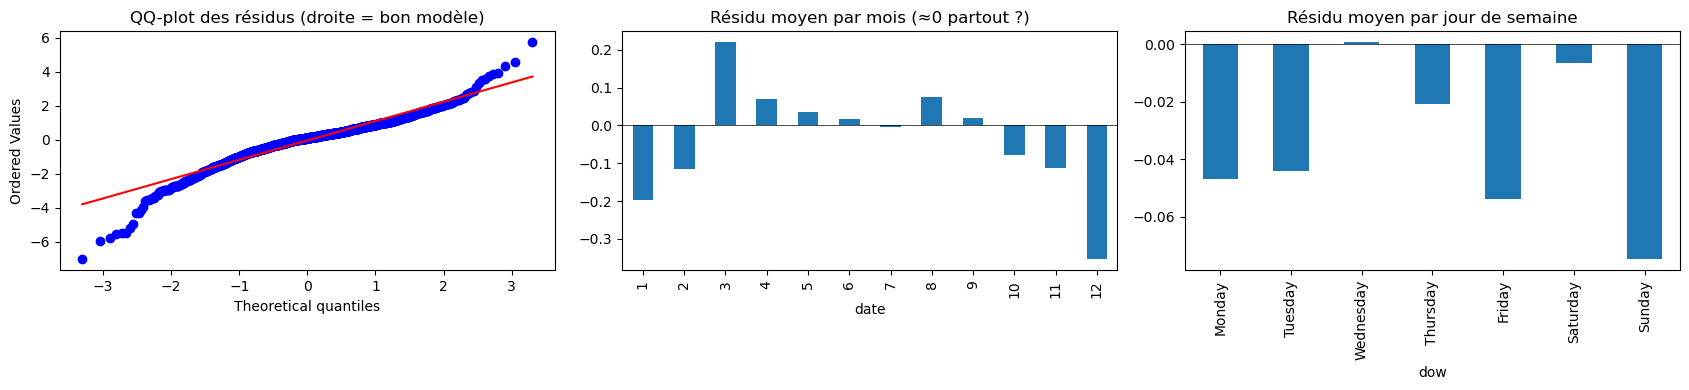

In [54]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
stats.probplot(zz, dist="norm", plot=ax[0]); ax[0].set_title("QQ-plot des résidus (droite = bon modèle)")
d.groupby(d.date.dt.month).z.mean().plot.bar(ax=ax[1]); ax[1].set_title("Résidu moyen par mois (≈0 partout ?)"); ax[1].axhline(0, c="k", lw=.5)
d.groupby("dow").z.mean().reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]).plot.bar(ax=ax[2])
ax[2].set_title("Résidu moyen par jour de semaine"); ax[2].axhline(0, c="k", lw=.5)
plt.tight_layout(); plt.show()

## 7. Observé vs attendu, avec les anomalies

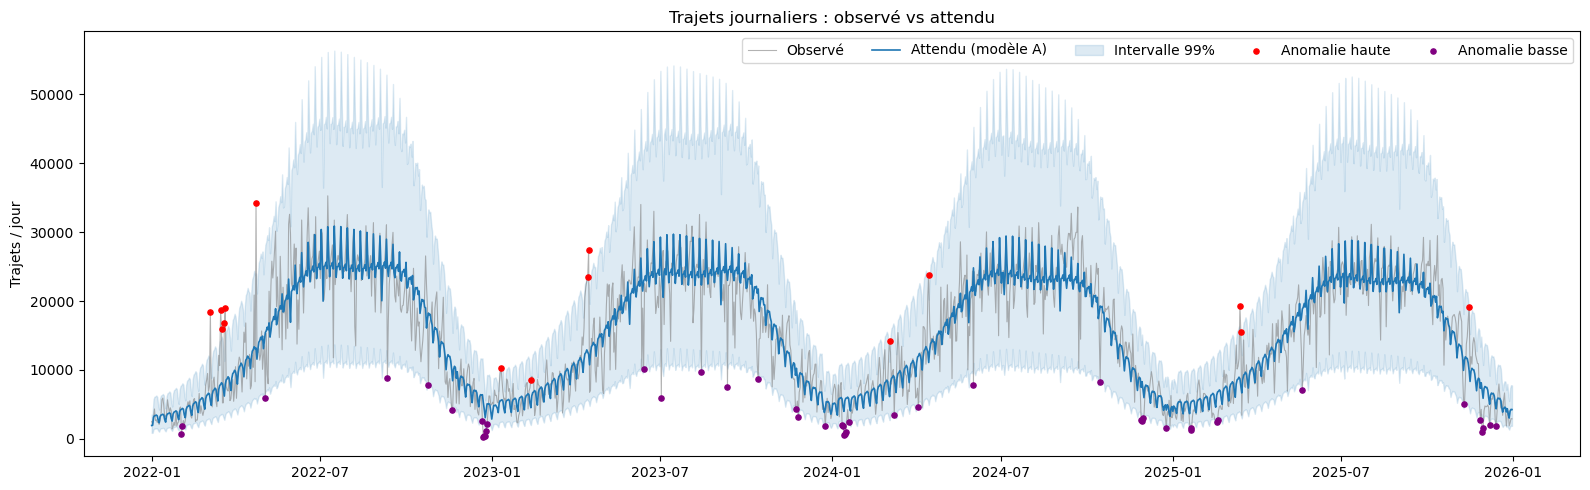

In [81]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(d.date, d.n_trips, color="gray", alpha=.6, lw=.8, label="Observé")
ax.plot(d.date, d.expected, color="tab:blue", lw=1.2, label="Attendu (modèle A)")
ax.fill_between(d.date, d.lower, d.upper, color="tab:blue", alpha=.15, label=f"Intervalle {LEVEL:.0%}")
a = d[d.is_anomaly]
ax.scatter(a.date[a.direction == "haut"], a.n_trips[a.direction == "haut"], c="red", s=14, label="Anomalie haute", zorder=5)
ax.scatter(a.date[a.direction == "bas"], a.n_trips[a.direction == "bas"], c="purple", s=14, label="Anomalie basse", zorder=5)
ax.set_title("Trajets journaliers : observé vs attendu"); ax.set_ylabel("Trajets / jour"); ax.legend(ncol=5); plt.tight_layout(); plt.show()

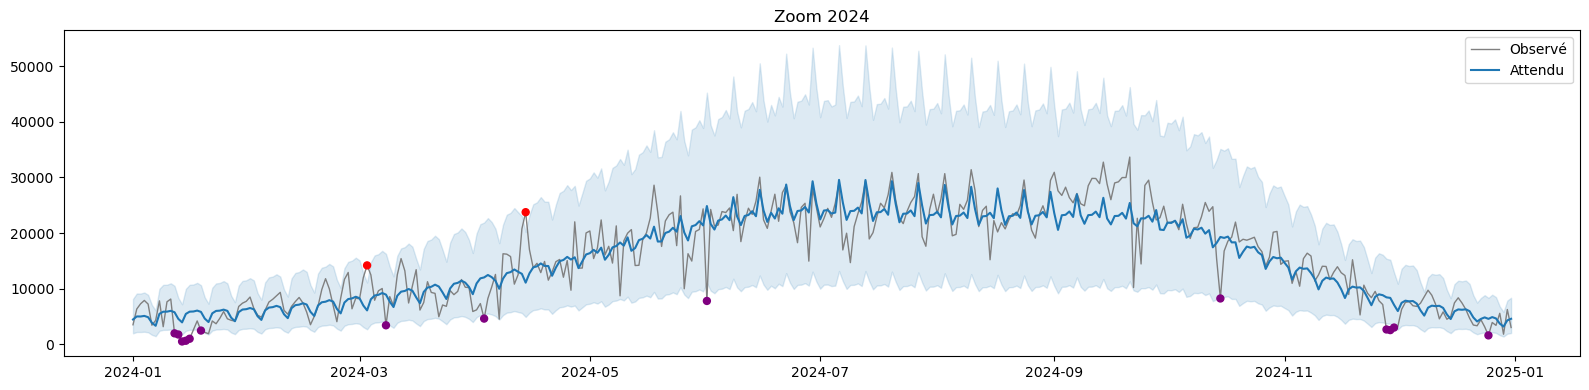

In [72]:
# Zoom sur une année (changer YEAR)
YEAR = 2024
s = d[d.date.dt.year == YEAR]
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(s.date, s.n_trips, color="gray", lw=1, label="Observé"); ax.plot(s.date, s.expected, color="tab:blue", label="Attendu")
ax.fill_between(s.date, s.lower, s.upper, color="tab:blue", alpha=.15)
sa = s[s.is_anomaly]; ax.scatter(sa.date, sa.n_trips, c=np.where(sa.direction == "haut", "red", "purple"), s=25, zorder=5)
ax.set_title(f"Zoom {YEAR}"); ax.legend(); plt.tight_layout(); plt.show()

## 8. Liste des jours anormaux
`ratio` = observé / attendu (2.0 = deux fois plus de trajets que prévu). Les jours déjà hors de l'ajustement (`in_fit=False`) sont les plus extrêmes.

In [73]:
d["in_fit"] = keep
anomalies = d.loc[d.is_anomaly, ["date", "dow", "holiday_name", "n_trips", "expected", "lower", "upper", "ratio", "z", "direction", "in_fit"]]
anomalies = anomalies.assign(abs_z=anomalies.z.abs()).sort_values("abs_z", ascending=False).drop(columns="abs_z")
print(f"{len(anomalies)} anomalies sur {len(d)} jours ({100*len(anomalies)/len(d):.1f} %)")
anomalies.round({c: 2 for c in ['expected', 'lower', 'upper', 'ratio', 'z']}).head(30)

62 anomalies sur 1461 jours (4.2 %)


,date,dow,holiday_name,n_trips,expected,lower,upper,ratio,z,direction,in_fit
387,2022-12-23,Friday,,261,5120.70,2281.0,9317.0,0.05,-7.03,bas,False
388,2022-12-24,Saturday,,464,4136.72,1842.0,7528.0,0.11,-5.92,bas,False
775,2024-01-15,Monday,Martin Luther King Jr. Day,671,5487.55,2445.0,9984.0,0.12,-5.75,bas,False
94,2022-03-05,Saturday,,18472,5516.31,2458.0,10037.0,3.35,5.74,haut,False
774,2024-01-14,Sunday,,540,3967.50,1767.0,7220.0,0.14,-5.52,bas,False
389,2022-12-25,Sunday,Christmas Day,468,3351.01,1492.0,6099.0,0.14,-5.46,bas,False
1459,2025-11-29,Saturday,,990,7042.07,3139.0,12811.0,0.14,-5.46,bas,False
63,2022-02-02,Wednesday,,685,4266.78,1900.0,7764.0,0.16,-5.16,bas,False
776,2024-01-16,Tuesday,,1029,5890.12,2625.0,10716.0,0.17,-4.98,bas,False
109,2022-03-20,Sunday,,16847,6198.19,2762.0,11277.0,2.72,4.57,haut,False


In [74]:
# Répartition des anomalies par année et par mois (des paquets = événement long, ex. COVID, ou modèle imparfait)
pd.crosstab(anomalies.date.dt.year, anomalies.direction).T

date,2022,2023,2024,2025
direction,,,,
bas,12,9,14,12
haut,6,4,2,3


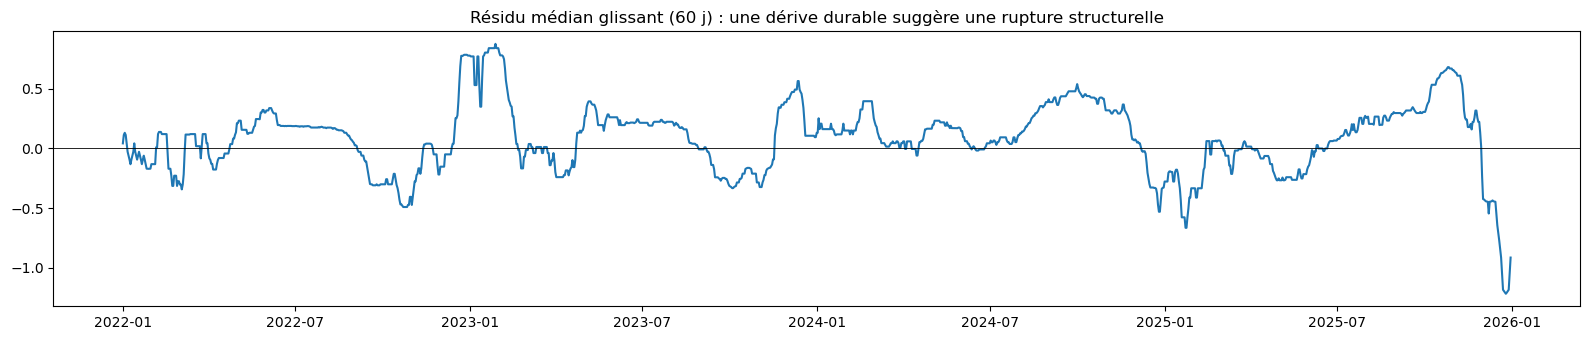

In [75]:
# Une dérive soutenue (courbe loin de 0 pendant des semaines) = niveau mal modélisé -> candidat à une rupture
roll = d.set_index("date").z.rolling(60, center=True, min_periods=30).median()
fig, ax = plt.subplots(figsize=(16, 3.5))
ax.plot(roll.index, roll.values); ax.axhline(0, c="k", lw=.6)
ax.set_title("Résidu médian glissant (60 j) : une dérive durable suggère une rupture structurelle")
plt.tight_layout(); plt.show()

-> many anomalities in "winter> ^robably explain by the weather !!!

## Saison ? 

In [60]:
# ======== NOUVELLE CELLULE : comparer plusieurs façons de modéliser la saison ========
CUT = "2025-01-01"
LEVEL_V = 0.99
dv = df.copy()
dv["month"] = dv.date.dt.month
for j in range(1, 9):                                   # jusqu'à 8 harmoniques disponibles
    dv[f"sin{j}"] = np.sin(2 * np.pi * j * dv.date.dt.dayofyear / 365.25)
    dv[f"cos{j}"] = np.cos(2 * np.pi * j * dv.date.dt.dayofyear / 365.25)

net = "log_network" if "log_network" in dv else "t"
extra = list(globals().get("calendar_terms", [])) + list(globals().get("step_terms", []))
base = ["C(dow)", "is_major_holiday", "wkend_sin1", "wkend_cos1", net, "is_winter_break", "is_spring_break"] + extra
fourier = lambda k: [f"{f}{j}" for j in range(1, k + 1) for f in ("sin", "cos")]

variants = {
    "3 harmoniques (actuel)":        base + fourier(3),
    "5 harmoniques":                 base + fourier(5),
    "8 harmoniques":                 base + fourier(8),
    "3 harm. + été scolaire":        base + fourier(3) + ["is_summer_break"],
    "5 harm. + été scolaire":        base + fourier(5) + ["is_summer_break"],
    "un coefficient par mois":       base + ["C(month)"],
}

def fit_nb_quiet(formula, data):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return smf.negativebinomial(formula, data).fit(disp=False, maxiter=500, method="bfgs")

train, test = dv[dv.date < CUT], dv[dv.date >= CUT]
q = (1 - LEVEL_V) / 2
rows = []
for name, terms in variants.items():
    f = "n_trips ~ " + " + ".join(terms)
    # (a) validation hors échantillon : ajusté sur < CUT, testé sur >= CUT
    m = fit_nb_quiet(f, train)
    mu = m.predict(test); lo, hi = nb_interval(mu, m.params["alpha"], LEVEL_V)
    yy = test.n_trips
    # (b) ajustement complet : quel mois est le plus mal modélisé ?
    mf = fit_nb_quiet(f, dv)
    z = quantile_resid(dv.n_trips, mf.predict(dv), mf.params["alpha"])
    by_month = z.groupby(dv.month).mean()
    rows.append({
        "variante": name,
        "pire mois (|z moyen|)": by_month.abs().max(),
        "mois": int(by_month.abs().idxmax()),
        "erreur % médiane (test)": 100 * np.median(np.abs(yy - mu) / yy),
        "couverture 99% (test)": 100 * np.mean((yy >= lo) & (yy <= hi)),
        "AIC (tout)": mf.aic,
    })
pd.DataFrame(rows).set_index("variante").round(2)

,pire mois (|z moyen|),mois,erreur % médiane (test),couverture 99% (test),AIC (tout)
variante,,,,,
3 harmoniques (actuel),0.20,1,15.91,96.46,29544.74
5 harmoniques,0.17,12,15.10,96.46,29539.78
8 harmoniques,0.15,1,15.21,96.21,29534.45
3 harm. + été scolaire,0.19,1,16.45,96.46,29545.46
5 harm. + été scolaire,0.17,12,15.00,96.21,29541.73
un coefficient par mois,0.14,1,18.48,96.97,29655.19


In [46]:
d.assign(year=d.date.dt.year, month=d.date.dt.month).pivot_table(index="month", columns="year", values="z", aggfunc="mean").round(2)

year,2022,2023,2024,2025
month,,,,
1,0.01,0.65,-0.90,-0.54
2,-0.64,0.25,0.46,-0.54
3,0.66,-0.27,0.15,0.34
4,0.09,0.29,-0.03,-0.07
5,0.35,0.16,0.07,-0.44
6,0.23,0.02,-0.08,-0.11
7,0.06,-0.08,-0.06,0.07
8,-0.02,0.02,0.06,0.26
9,-0.29,-0.41,0.61,0.17


In [34]:
# ======== NOUVELLE CELLULE (après la cellule du modèle) : validation hors échantillon + Poisson / NB / linéaire ========
import statsmodels.api as sm

CUT = "2025-01-01"                      # on ajuste avant CUT, on teste après (ordre chronologique, jamais de mélange aléatoire)
LEVEL_V = 0.99

# Spline de repli : impossible à extrapoler hors de la période d'ajustement -> on prend un terme linéaire pour ce test
net = "log_network" if "log_network" in df else "t"
rhs = " + ".join(["C(dow)", "is_major_holiday", "wkend_sin1", "wkend_cos1", net] + break_terms + harm)

train, test = df[df.date < CUT], df[df.date >= CUT]
y = test.n_trips.values
q = (1 - LEVEL_V) / 2
rows = {}

# 1) Poisson
m = smf.glm("n_trips ~ " + rhs, train, family=sm.families.Poisson()).fit()
mu = m.predict(test)
lo, hi = stats.poisson.ppf(q, mu), stats.poisson.ppf(1 - q, mu)
rows["Poisson"] = (mu, lo, hi, m.aic, m.bic_llf)

# 2) Binomiale négative (α estimé)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m = smf.negativebinomial("n_trips ~ " + rhs, train).fit(disp=False, maxiter=500, method="bfgs")
mu = m.predict(test)
lo, hi = nb_interval(mu, m.params["alpha"], LEVEL_V)
rows["Binomiale négative"] = (mu, lo, hi, m.aic, m.bic)

# 3) Régression linéaire sur log(trajets)
m = smf.ols("np.log(n_trips) ~ " + rhs, train).fit()
pred = m.predict(test)
s = np.sqrt(m.scale)
mu = np.exp(pred + s**2 / 2)
lo, hi = np.exp(pred + stats.norm.ppf(q) * s), np.exp(pred + stats.norm.ppf(1 - q) * s)
rows["Linéaire (log)"] = (mu, lo, hi, np.nan, np.nan)   # AIC non comparable (échelle log)

out = []
for name, (mu, lo, hi, aic, bic) in rows.items():
    mu, lo, hi = map(np.asarray, (mu, lo, hi))
    out.append({
        "modèle": name,
        "erreur % médiane (test)": 100 * np.median(np.abs(y - mu) / y),
        f"couverture {LEVEL_V:.0%} (test)": 100 * np.mean((y >= lo) & (y <= hi)),
        "largeur médiane intervalle / attendu": np.median((hi - lo) / mu),
        "AIC (train)": aic,
    })
pd.DataFrame(out).set_index("modèle").round(2)

,erreur % médiane (test),couverture 99% (test),largeur médiane intervalle / attendu,AIC (train)
modèle,,,,
Poisson,14.16,10.14,0.04,1089264.70
Binomiale négative,15.29,97.53,1.67,21367.81
Linéaire (log),20.70,96.99,1.97,NaN


## 9. Export
`daily_expected.csv` (toutes les valeurs attendues) et `anomalies.csv` : à partager avec l'équipe pour la mise en correspondance avec les événements.

In [61]:
import os
os.makedirs("data", exist_ok=True)
d[["date", "n_trips", "expected", "lower", "upper", "z", "is_anomaly", "direction", "ratio"]].to_csv("data/daily_expected.csv", index=False)
anomalies.to_csv("data/anomalies.csv", index=False)
print("Fichiers écrits : data/daily_expected.csv, data/anomalies.csv")

Fichiers écrits : data/daily_expected.csv, data/anomalies.csv


Écrit : data/model_A_summary.json, data/model_A_monthly_residuals.csv
=== TOP 15 anomalies (toutes saisons) ===


,date,dow,season,n_trips,expected,ratio,z,direction,ratio_prev,ratio_next,context
356,2022-12-23,Friday,hiver,261,5120.70,0.05,-7.03,bas,0.39,0.11,winter_break
357,2022-12-24,Saturday,hiver,464,4136.72,0.11,-5.92,bas,0.05,0.14,"long_weekend, winter_break"
744,2024-01-15,Monday,hiver,671,5487.55,0.12,-5.75,bas,0.14,0.17,Martin Luther King Jr. Day
63,2022-03-05,Saturday,printemps,18472,5516.31,3.35,5.74,haut,1.17,1.34,
743,2024-01-14,Sunday,hiver,540,3967.50,0.14,-5.52,bas,0.39,0.12,
358,2022-12-25,Sunday,hiver,468,3351.01,0.14,-5.46,bas,0.11,0.27,"Christmas Day, winter_break"
1428,2025-11-29,Saturday,automne,990,7042.07,0.14,-5.46,bas,0.52,0.25,thanksgiving_week
32,2022-02-02,Wednesday,hiver,685,4266.78,0.16,-5.16,bas,1.10,0.42,
745,2024-01-16,Tuesday,hiver,1029,5890.12,0.17,-4.98,bas,0.12,0.45,
78,2022-03-20,Sunday,printemps,16847,6198.19,2.72,4.57,haut,0.74,2.41,


=== TOP 10 anomalies d'été (les plus fiables : peu sensibles à la météo) ===


,date,dow,season,n_trips,expected,ratio,z,direction,ratio_prev,ratio_next,context
547,2023-07-02,Sunday,été,5978,25319.54,0.24,-4.28,bas,0.75,1.16,
882,2024-06-01,Saturday,été,7815,24861.51,0.31,-3.55,bas,1.14,1.12,
590,2023-08-14,Monday,été,9645,22093.63,0.44,-2.64,bas,0.91,0.93,
528,2023-06-13,Tuesday,été,10163,22838.62,0.44,-2.58,bas,0.90,0.98,


=== Suspects : possible problème de données (ratio < 0.2 ou > 3) ===


,date,dow,season,n_trips,expected,ratio,z,direction,ratio_prev,ratio_next,context
356,2022-12-23,Friday,hiver,261,5120.70,0.05,-7.03,bas,0.39,0.11,winter_break
357,2022-12-24,Saturday,hiver,464,4136.72,0.11,-5.92,bas,0.05,0.14,"long_weekend, winter_break"
744,2024-01-15,Monday,hiver,671,5487.55,0.12,-5.75,bas,0.14,0.17,Martin Luther King Jr. Day
63,2022-03-05,Saturday,printemps,18472,5516.31,3.35,5.74,haut,1.17,1.34,
743,2024-01-14,Sunday,hiver,540,3967.50,0.14,-5.52,bas,0.39,0.12,
358,2022-12-25,Sunday,hiver,468,3351.01,0.14,-5.46,bas,0.11,0.27,"Christmas Day, winter_break"
1428,2025-11-29,Saturday,automne,990,7042.07,0.14,-5.46,bas,0.52,0.25,thanksgiving_week
32,2022-02-02,Wednesday,hiver,685,4266.78,0.16,-5.16,bas,1.10,0.42,
745,2024-01-16,Tuesday,hiver,1029,5890.12,0.17,-4.98,bas,0.12,0.45,


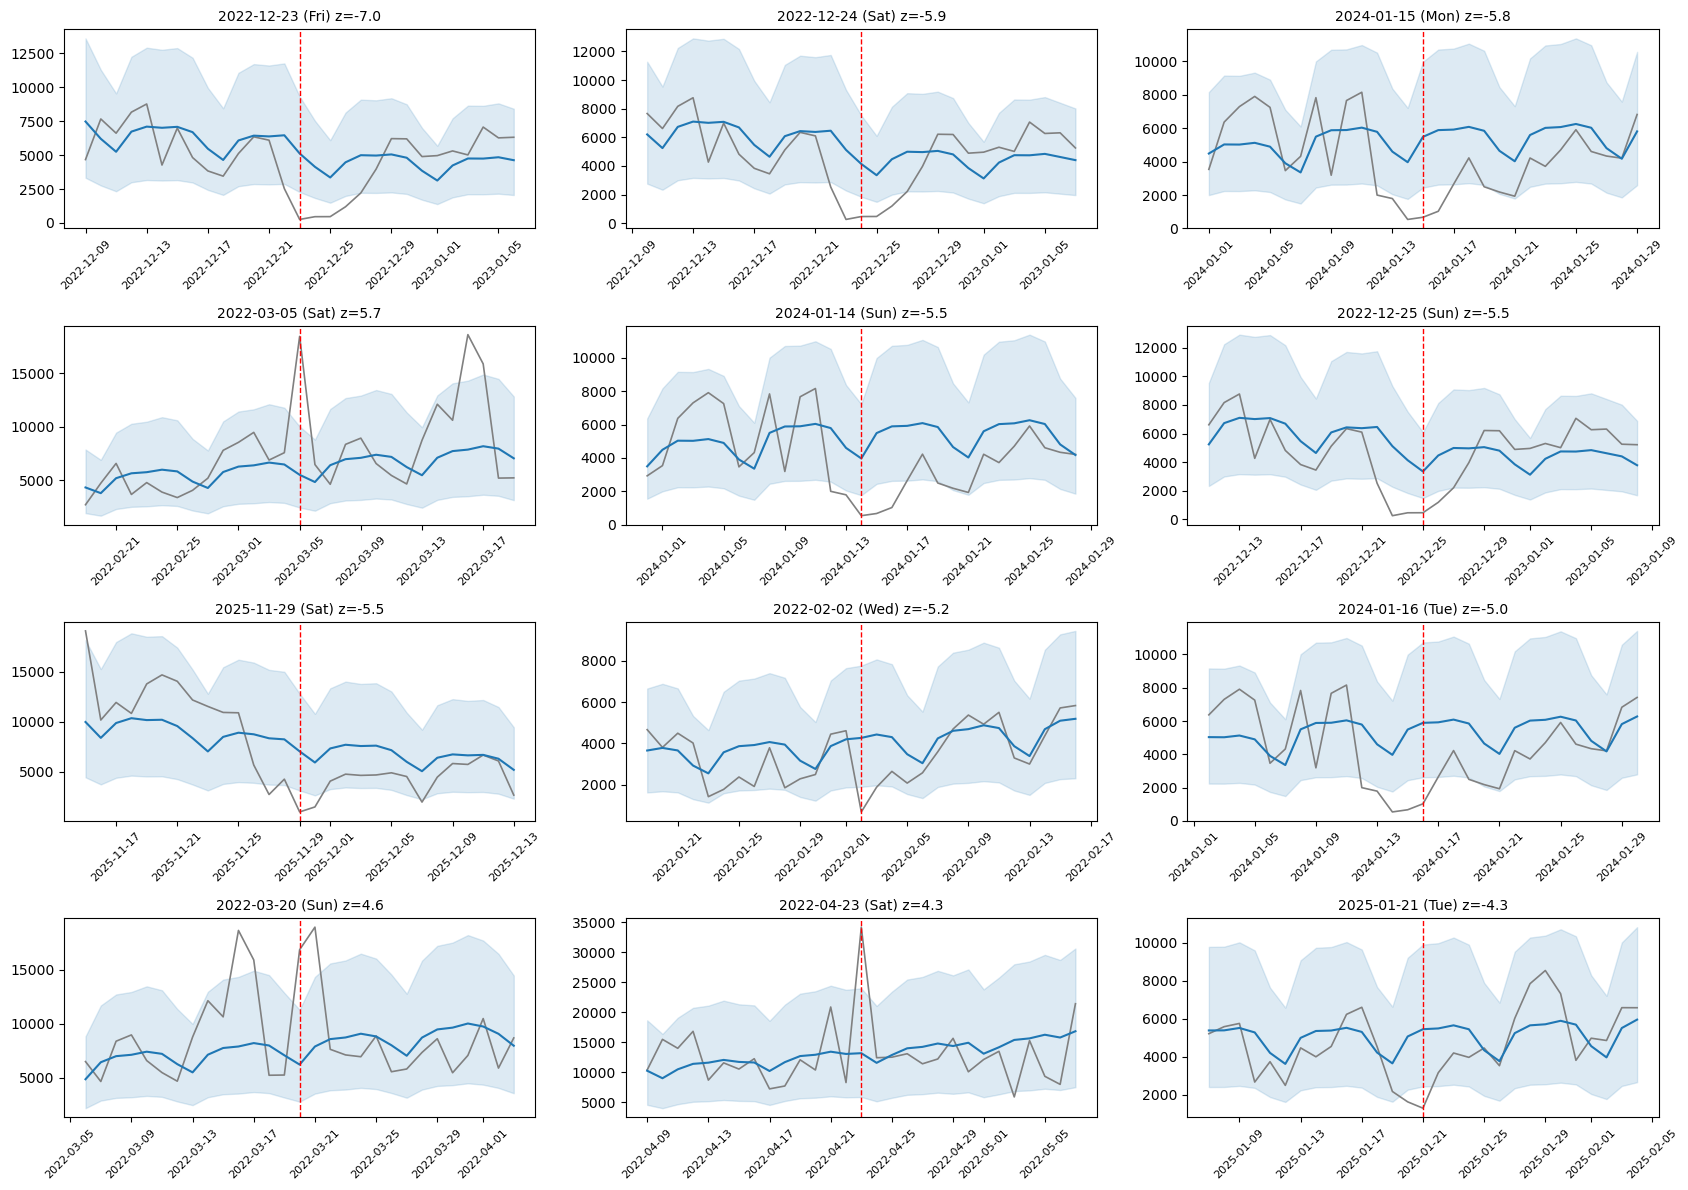

62 jours anormaux regroupés en 40 épisodes -> data/daily_expected_A.csv, anomaly_days_A.csv, anomaly_episodes_A.csv


,episode_id,start,end,n_days,n_anomalous_days,direction,peak_date,peak_z,mean_ratio,excess_trips,season,context
9,10,2022-12-22,2022-12-27,6,6,bas,2022-12-23,-7.03,0.23,-21401,hiver,winter_break
20,21,2024-01-12,2024-01-16,5,5,bas,2024-01-15,-5.75,0.23,-19703,hiver,Martin Luther King Jr. Day
1,2,2022-03-05,2022-03-05,1,1,haut,2022-03-05,5.74,3.35,12955,printemps,
36,37,2025-11-27,2025-11-30,4,3,bas,2025-11-29,-5.46,0.31,-20085,automne,thanksgiving_week
0,1,2022-02-02,2022-02-03,2,2,bas,2022-02-02,-5.16,0.29,-6131,hiver,
3,4,2022-03-20,2022-03-21,2,2,haut,2022-03-20,4.57,2.56,21713,printemps,
4,5,2022-04-23,2022-04-23,1,1,haut,2022-04-23,4.33,2.59,21004,printemps,
14,15,2023-07-02,2023-07-02,1,1,bas,2023-07-02,-4.28,0.24,-19341,été,
30,31,2025-01-20,2025-01-21,2,2,bas,2025-01-21,-4.28,0.28,-7610,hiver,
2,3,2022-03-16,2022-03-17,2,2,haut,2022-03-16,3.85,2.15,18464,printemps,


In [76]:
# ================================================================================================
# CELLULE 1 — FIGER LE MODÈLE A (à lancer après la cellule du modèle ET après avoir restreint d à la fenêtre de rapport)
# ================================================================================================
import json, os
os.makedirs("data", exist_ok=True)
if "in_fit" not in d:
    d["in_fit"] = keep

# --- validation hors échantillon : ajusté avant CUT, testé en 2025 ---
CUT = "2025-01-01"
net = "log_network" if "log_network" in df else "t"      # une spline ne s'extrapole pas -> terme linéaire pour ce test
rhs = " + ".join(["C(dow)", "is_major_holiday", "wkend_sin1", "wkend_cos1", net] + break_terms + harm)
train = df[df.date < CUT]
test = df[(df.date >= CUT) & (df.date <= REPORT_END)]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m_ = smf.negativebinomial("n_trips ~ " + rhs, train).fit(disp=False, maxiter=500, method="bfgs")
mu_t = m_.predict(test)
lo_t, hi_t = nb_interval(mu_t, m_.params["alpha"], LEVEL)
yy = test.n_trips

# --- tableau mois x année des résidus moyens ---
monthly = d.assign(year=d.date.dt.year, month=d.date.dt.month).pivot_table(
    index="month", columns="year", values="z", aggfunc="mean")

zz = d.z.dropna()
summary = {
    "fenetre_ajustement": [START, END],
    "fenetre_rapport": [REPORT_START, REPORT_END],
    "formule": " ".join(formula.split()),
    "jours_ajustement_robuste": int(keep.sum()),
    "jours_rapport": int(len(d)),
    "alpha": round(float(alpha), 4),
    "AIC": round(float(res.aic), 1),
    "z_moyen": round(float(zz.mean()), 3),
    "z_ecart_type": round(float(zz.std()), 3),
    "niveau_intervalle": LEVEL,
    "pct_jours_anormaux": round(100 * float(d.is_anomaly.mean()), 2),
    "autocorr_lag1": round(float(acf(zz, nlags=1)[1]), 3),
    "pire_mois_abs_z_moyen": round(float(monthly.abs().max().max()), 2),
    "holdout_erreur_pct_mediane": round(100 * float(np.median(np.abs(yy - mu_t) / yy)), 2),
    "holdout_couverture_pct": round(100 * float(np.mean((yy >= lo_t) & (yy <= hi_t))), 2),
    "holdout_largeur_mediane_sur_attendu": round(float(np.median((hi_t - lo_t) / mu_t)), 2),
}
with open("data/model_A_summary.json", "w") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
monthly.round(3).to_csv("data/model_A_monthly_residuals.csv")
print("Écrit : data/model_A_summary.json, data/model_A_monthly_residuals.csv")
pd.Series(summary).to_frame("valeur")


# ================================================================================================
# CELLULE 2 — REVUE MANUELLE DES PLUS GROSSES ANOMALIES
# ================================================================================================
from IPython.display import display

SEASONS = {12: "hiver", 1: "hiver", 2: "hiver", 3: "printemps", 4: "printemps", 5: "printemps",
           6: "été", 7: "été", 8: "été", 9: "automne", 10: "automne", 11: "automne"}
d = d.sort_values("date").reset_index(drop=True)
d["season"] = d.date.dt.month.map(SEASONS)
d["ratio_prev"], d["ratio_next"] = d.ratio.shift(1), d.ratio.shift(-1)   # voisins : pic isolé ou période continue ?

flag_cols = [c for c in ["is_long_weekend", "is_holiday_eve", "is_thanksgiving_week",
                         "is_winter_break", "is_spring_break"] if c in d.columns]
def context(r):
    parts = [r.holiday_name] if isinstance(r.holiday_name, str) and r.holiday_name else []
    parts += [c.replace("is_", "") for c in flag_cols if r[c]]
    return ", ".join(parts)
d["context"] = d.apply(context, axis=1)

show = ["date", "dow", "season", "n_trips", "expected", "ratio", "z", "direction", "ratio_prev", "ratio_next", "context"]
an = d[d.is_anomaly].assign(abs_z=lambda x: x.z.abs()).sort_values("abs_z", ascending=False)

print("=== TOP 15 anomalies (toutes saisons) ===")
display(an.head(15)[show].round(2))
print("=== TOP 10 anomalies d'été (les plus fiables : peu sensibles à la météo) ===")
display(an[an.season == "été"].head(10)[show].round(2))
print("=== Suspects : possible problème de données (ratio < 0.2 ou > 3) ===")
display(an[(an.ratio < 0.2) | (an.ratio > 3)][show].round(2))

# Zoom ±14 jours autour des 12 plus grosses anomalies
top = an.head(12)
fig, axes = plt.subplots(4, 3, figsize=(17, 12))
axes = axes.ravel()
for ax in axes:
    ax.axis("off")
for ax, (_, r) in zip(axes, top.iterrows()):
    ax.axis("on")
    w = d[(d.date >= r.date - pd.Timedelta(days=14)) & (d.date <= r.date + pd.Timedelta(days=14))]
    ax.plot(w.date, w.n_trips, color="gray", lw=1.2)
    ax.plot(w.date, w.expected, color="tab:blue")
    ax.fill_between(w.date, w.lower, w.upper, color="tab:blue", alpha=.15)
    ax.axvline(r.date, color="red", ls="--", lw=1)
    ax.set_title(f"{r.date:%Y-%m-%d} ({r.dow[:3]}) z={r.z:.1f}", fontsize=10)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
plt.tight_layout(); plt.show()


# ================================================================================================
# CELLULE 3 — ÉPISODES + EXPORT POUR LA MISE EN CORRESPONDANCE AVEC LES ÉVÉNEMENTS
# Un événement dure souvent plusieurs jours : on regroupe les jours anormaux consécutifs en « épisodes ».
# ================================================================================================
a = d[d.is_anomaly].sort_values("date").copy()
gap = a.date.diff().dt.days.fillna(99)
a["episode_id"] = ((gap > 2) | (a.direction != a.direction.shift())).cumsum()   # trou d'1 jour toléré

rows = []
for eid, g in a.groupby("episode_id"):
    span = d[(d.date >= g.date.min()) & (d.date <= g.date.max())]
    peak = g.loc[g.z.abs().idxmax()]
    rows.append({
        "episode_id": eid, "start": g.date.min(), "end": g.date.max(),
        "n_days": len(span), "n_anomalous_days": len(g), "direction": peak.direction,
        "peak_date": peak.date, "peak_z": round(peak.z, 2),
        "mean_ratio": round(span.ratio.mean(), 2),
        "excess_trips": int((span.n_trips - span.expected).sum()),
        "season": peak.season, "context": peak.context,
    })
episodes = pd.DataFrame(rows)

# --- exports ---
daily_cols = ["date", "n_trips", "expected", "lower", "upper", "z", "ratio", "is_anomaly", "direction", "in_fit", "season", "context"]
d[daily_cols].to_csv("data/daily_expected_A.csv", index=False)
a[["date", "n_trips", "expected", "ratio", "z", "direction", "season", "context", "episode_id"]].to_csv("data/anomaly_days_A.csv", index=False)
episodes.to_csv("data/anomaly_episodes_A.csv", index=False)
print(f"{len(a)} jours anormaux regroupés en {len(episodes)} épisodes -> data/daily_expected_A.csv, anomaly_days_A.csv, anomaly_episodes_A.csv")

# --- fonction de mise en correspondance (à utiliser quand le fichier d'événements est prêt) ---
def match_events(episodes, events, start_col="start", end_col="end", name_col="event_name", tol_days=1):
    """events : DataFrame avec 2 colonnes de dates (start/end, identiques si événement d'un jour) et un nom.
    Un épisode est associé à un événement si leurs périodes se chevauchent, à +/- tol_days près."""
    out = []
    for _, e in episodes.iterrows():
        s, t = e.start - pd.Timedelta(days=tol_days), e.end + pd.Timedelta(days=tol_days)
        hit = events[(events[start_col] <= t) & (events[end_col] >= s)]
        out.append("; ".join(hit[name_col].astype(str)) if len(hit) else "")
    return episodes.assign(matched_events=out)

episodes.sort_values("peak_z", key=abs, ascending=False).head(15)

Part des fériés plus proches d'un dimanche que d'un jour de semaine : 69 % (26 fériés)


,n,vs_semaine,vs_dimanche,pct_proche_dimanche
férié,,,,
Christmas Day,5,0.25,0.41,100.0
Thanksgiving Day,4,0.34,0.51,100.0
Memorial Day,4,0.98,1.02,50.0
Labor Day,4,1.06,1.03,75.0
Independence Day,4,1.01,1.05,0.0
New Year's Day,5,0.71,1.07,80.0


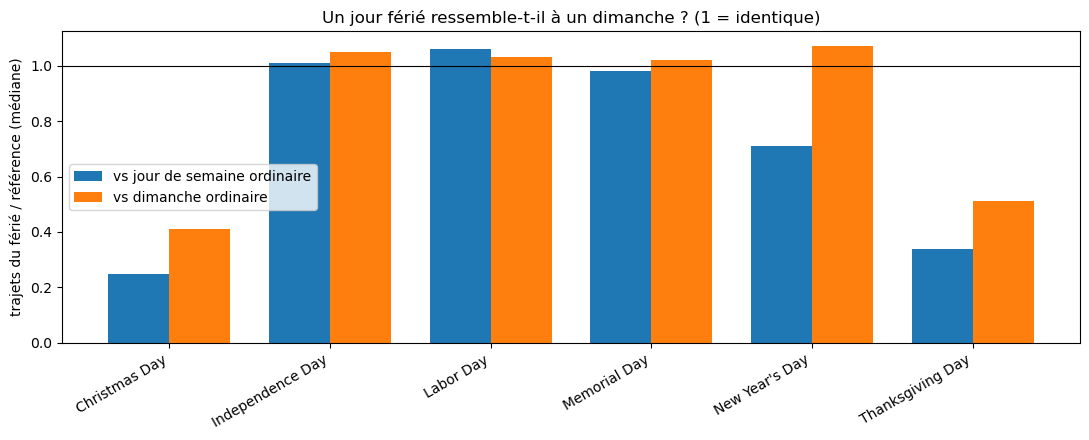

Changements d'heure : ['2022-03-13 (-1h)', '2022-11-06 (+1h)', '2023-03-12 (-1h)', '2023-11-05 (+1h)', '2024-03-10 (-1h)', '2024-11-03 (+1h)', '2025-03-09 (-1h)', '2025-11-02 (+1h)']


,z moyen,jours
jour du changement,0.58,8
7 jours après,0.56,56
autres jours,-0.06,1397


In [83]:
# CELLULE 1 — HYPOTHÈSE « UN JOUR FÉRIÉ RESSEMBLE À UN DIMANCHE » (jours fériés vs jours de semaine vs dimanches)
# Pour chaque férié majeur : on compare au même voisinage (±21 jours) : jours de semaine ordinaires et dimanches ordinaires.
# ================================================================================================
WINDOW = 21
base = d[["date", "n_trips", "dow", "is_major_holiday"]].copy()
base["is_ordinary"] = ~base.is_major_holiday
hol = d[d.is_major_holiday].copy()
 
rows = []
for _, h in hol.iterrows():
    w = base[(base.date >= h.date - pd.Timedelta(days=WINDOW)) & (base.date <= h.date + pd.Timedelta(days=WINDOW)) & base.is_ordinary]
    wk = w[w.dow.isin(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])].n_trips.mean()
    sun = w[w.dow == "Sunday"].n_trips.mean()
    rows.append({"date": h.date, "férié": h.holiday_name.replace(" (observed)", ""), "jour": h.dow,
                 "n_trips": h.n_trips, "ratio_vs_semaine": h.n_trips / wk, "ratio_vs_dimanche": h.n_trips / sun})
hv = pd.DataFrame(rows)
hv["plus_proche_de"] = np.where(np.abs(np.log(hv.ratio_vs_dimanche)) < np.abs(np.log(hv.ratio_vs_semaine)), "dimanche", "semaine")
 
by_name = hv.groupby("férié").agg(n=("date", "size"),
                                  vs_semaine=("ratio_vs_semaine", "median"),
                                  vs_dimanche=("ratio_vs_dimanche", "median"),
                                  pct_proche_dimanche=("plus_proche_de", lambda s: 100 * (s == "dimanche").mean())).round(2)
print(f"Part des fériés plus proches d'un dimanche que d'un jour de semaine : {100*(hv.plus_proche_de=='dimanche').mean():.0f} % ({len(hv)} fériés)")
display(by_name.sort_values("vs_dimanche"))
 
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(by_name)); wd = 0.38
ax.bar(x - wd/2, by_name.vs_semaine, wd, label="vs jour de semaine ordinaire")
ax.bar(x + wd/2, by_name.vs_dimanche, wd, label="vs dimanche ordinaire")
ax.axhline(1, c="k", lw=.8); ax.set_xticks(x); ax.set_xticklabels(by_name.index, rotation=30, ha="right")
ax.set_ylabel("trajets du férié / référence (médiane)"); ax.set_title("Un jour férié ressemble-t-il à un dimanche ? (1 = identique)")
ax.legend(); plt.tight_layout(); plt.show()
 
 
# ================================================================================================
# CELLULE 2 — CHANGEMENTS D'HEURE (DST) : effet sur les trajets ?
# Jours de changement détectés automatiquement (jour de 23 h ou 25 h à Chicago), pas à la main.
# ================================================================================================
idx = pd.date_range(START, pd.Timestamp(END) + pd.Timedelta(days=1), freq="D", tz="America/Chicago")
day_len = pd.Series(idx[1:] - idx[:-1], index=idx[:-1].tz_localize(None))
dst_days = day_len[day_len != pd.Timedelta(hours=24)].index
print("Changements d'heure :", [f"{x:%Y-%m-%d} ({'+1h' if day_len[x] > pd.Timedelta(hours=24) else '-1h'})" for x in dst_days])
 
dd = d.copy()
dd["dst_day"] = dd.date.isin(dst_days)
dd["dst_week_after"] = False
for x in dst_days:
    dd.loc[(dd.date > x) & (dd.date <= x + pd.Timedelta(days=7)), "dst_week_after"] = True
res_dst = pd.DataFrame({
    "z moyen": [dd[dd.dst_day].z.mean(), dd[dd.dst_week_after].z.mean(), dd[~dd.dst_day & ~dd.dst_week_after].z.mean()],
    "jours": [int(dd.dst_day.sum()), int(dd.dst_week_after.sum()), int((~dd.dst_day & ~dd.dst_week_after).sum())]},
    index=["jour du changement", "7 jours après", "autres jours"]).round(2)
display(res_dst)
# Lecture : si le z moyen des 7 jours après est proche de celui des autres jours (±0.3), un drapeau DST n'est pas utile.

In [63]:
d[d.date.dt.strftime("%m-%d").isin(["12-24", "12-25", "12-26", "01-01"])][["date", "n_trips", "expected", "ratio", "z"]]

,date,n_trips,expected,ratio,z
0,2022-01-01,2514,2101.591575,1.196236,0.778752
357,2022-12-24,464,4136.717124,0.112166,-5.922991
358,2022-12-25,468,3351.005927,0.139660,-5.461669
359,2022-12-26,1195,4469.661700,0.267358,-3.957872
365,2023-01-01,4962,3125.330143,1.587672,1.960566
722,2023-12-24,4117,3743.211359,1.099858,0.450328
723,2023-12-25,1836,4737.571022,0.387540,-2.972840
724,2023-12-26,4320,5292.128049,0.816307,-0.645561
730,2024-01-01,3539,4487.968660,0.788553,-0.765157
1088,2024-12-24,3173,4864.358912,0.652296,-1.402559


## Pistes suivantes
1. **Ajouter la taille du réseau** (stations actives / jour calculées depuis les trajets) → colonne `n_active_stations`.
2. Modèle B : ajouter la météo (hors périmètre pour l'instant) et comparer les anomalies A vs B.
3. Vérifier les anomalies qui se regroupent (COVID 2020, 2013 démarrage) : décider si elles font partie du « normal ».
4. Correspondance avec les événements (jeu de données Public Health Department) via les résidus, pas via les moyennes.